# 02 — Policy gradients and actor-critic

## Learning objectives

- Derive log-probability policy gradients and action-independent baselines.
- Train REINFORCE on a contextual bandit.
- Fit a value head and compute GAE with correct terminal handling.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** Notes Chapters01/04 and RLHF PDF actor/critic and reward8/value6 examples. This notebook adds complete trainable policy/baseline examples.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## REINFORCE and the score-function identity

$$
\nabla_\theta J=\mathbb E_\tau\left[G_0\sum_t\nabla_\theta\log\pi_\theta(a_t\mid s_t)\right].
$$
$J$ is expected return, $\theta$ policy parameters, $\tau$ a trajectory, and $\pi$ action distribution. The identity $\nabla p=p\nabla\log p$ explains log probabilities. Causality permits reward-to-go; a discounted start-state estimator also weights time $t$ by $\gamma^t$. Here episodes have one action and $\gamma=1$.

$$
A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s),\qquad \mathcal L_{actor}=-\mathbb E[\log\pi_\theta(a\mid s)\hat A].
$$
$Q$ predicts action-conditioned return, $V$ average return, $A$ advantage. Subtracting an action-independent baseline does not change the expected score-function gradient. Detach estimated advantages when optimizing the actor; fit the critic separately.

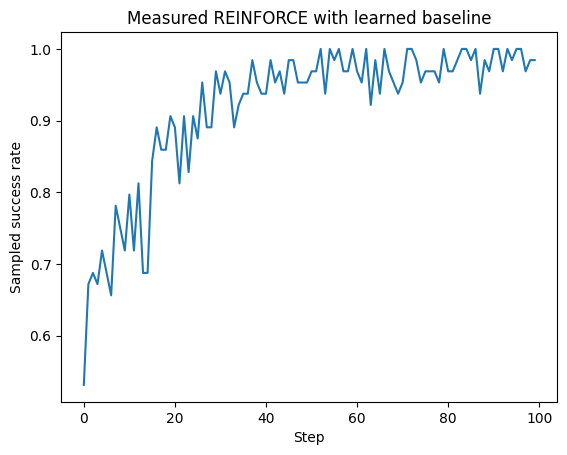

Learned action probabilities: tensor([[0.9858, 0.0142],
        [0.0141, 0.9859]])


In [2]:
# Synthetic contextual bandit: action should match context 0 or 1.
actor=nn.Linear(2,2);critic=nn.Linear(2,1)
opt=torch.optim.Adam(list(actor.parameters())+list(critic.parameters()),lr=.04)
measured=[]
for step in range(100):
    context=torch.randint(0,2,(64,));x=F.one_hot(context,2).float()
    dist=torch.distributions.Categorical(logits=actor(x));action=dist.sample()
    reward=action.eq(context).float();value=critic(x).squeeze(-1)
    advantage=reward-value.detach()
    actor_loss=-(dist.log_prob(action)*advantage).mean()
    value_loss=.5*(value-reward).square().mean()
    loss=actor_loss+value_loss-.01*dist.entropy().mean()
    opt.zero_grad();loss.backward()
    assert actor.weight.grad.abs().sum()>0 and critic.weight.grad.abs().sum()>0
    assert torch.isfinite(loss);opt.step();measured.append(reward.mean().item())
plt.plot(measured);plt.xlabel('Step');plt.ylabel('Sampled success rate');plt.title('Measured REINFORCE with learned baseline');plt.show()
with torch.no_grad():print('Learned action probabilities:',actor(torch.eye(2)).softmax(-1))

## Generalized Advantage Estimation

$$
\delta_t=R_t+\gamma(1-d_t)V_{old}(s_{t+1})-V_{old}(s_t),\qquad
\hat A_t=\delta_t+\gamma\lambda(1-b_t)\hat A_{t+1},\qquad \hat G_t=\hat A_t^{raw}+V_{old}(s_t).
$$
$\delta$ is TD residual, $d$ true terminal, $b$ episode boundary (terminal or time-limit reset), $\lambda$ residual decay, and $\hat G$ detached value target. Fixed rollout critic $V_{old}$ must be used consistently. A truncation bootstraps its final observation but stops recursion across a reset. Normalize actor advantages only after calculating critic targets. With rewards $[0,1]$, values $[.4,.5]$, $\gamma=1$, $\lambda=.95$, advantages are $[.575,.5]$.

In [3]:
def gae(rewards,values,next_values,terminated,boundary,gamma=.99,lam=.95):
    # terminated: true MDP terminal -> no bootstrap.
    # boundary: terminal OR time-limit/reset boundary -> no cross-episode recursion.
    # For a truncation next_values uses the pre-reset final observation.
    assert rewards.shape==values.shape==next_values.shape==terminated.shape==boundary.shape
    delta=rewards+gamma*(~terminated).float()*next_values-values
    advantages=torch.zeros_like(rewards);carry=torch.zeros_like(rewards[-1])
    for t in reversed(range(len(rewards))):
        carry=delta[t]+gamma*lam*(~boundary[t]).float()*carry
        advantages[t]=carry
    return advantages.detach(),(advantages+values).detach()
r=torch.tensor([0.,1.]);v=torch.tensor([.4,.5]);nv=torch.tensor([.5,0.]);d=torch.tensor([False,True])
a,target=gae(r,v,nv,d,d,1.,.95)
assert torch.allclose(a,torch.tensor([.575,.5])) and torch.allclose(target,torch.tensor([.975,1.]))
# Distinguish time-limit bootstrap from true terminal.
a_tr,_=gae(torch.tensor([0.]),torch.tensor([.2]),torch.tensor([.7]),torch.tensor([False]),torch.tensor([True]),1.,.95)
assert torch.allclose(a_tr,torch.tensor([.5]))
print('GAE and truncation tests passed:',a.tolist(),target.tolist())

GAE and truncation tests passed: [0.574999988079071, 0.5] [0.9750000238418579, 1.0]


In [4]:
# Why detach matters: actor advantages must not turn critic into an actor-loss shortcut.
value=torch.tensor([.3],requires_grad=True);logp=torch.tensor([-.7],requires_grad=True)
actor_loss=-(logp*(torch.tensor([1.])-value).detach()).mean()
actor_loss.backward();assert value.grad is None and logp.grad is not None
print('Detached baseline blocks critic gradient from actor objective.')

Detached baseline blocks critic gradient from actor objective.


## Exercises

1. Compare no baseline, moving-average baseline and learned baseline.
2. Sweep GAE lambda and recompute targets.
3. Remove detach in a copy and inspect which gradients change.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.